# Events and features for one subject across all nine runs

This notebook loads the first subject (lexicographically) only, enriches each of that subject's nine `events.tsv` tables using `Meg(add_features=True)`, and concatenates them into `all_events`. The `word_frequency` tables and saved Whisper transcripts required by `Meg` must already be available. Filtering and Maxwell processing are disabled.

In [1]:
from pathlib import Path
import re
import sys

import pandas as pd

project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / 'config.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate config.py from the current directory')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config import LISTEN_DIR
from meg import Meg

events_paths = sorted(
    LISTEN_DIR.glob("sub-*/ses-01/meg/*_task-listen_run-*_events.tsv")
)
if not events_paths:
    raise FileNotFoundError(f"No listening-run events.tsv files found under {LISTEN_DIR}")

first_subject = events_paths[0].parents[2].name
subject_events_paths = [
    path for path in events_paths if path.parents[2].name == first_subject
]

run_paths = {}
for path in subject_events_paths:
    match = re.search(r"_run-(\d+)_events\.tsv$", path.name)
    if match is None:
        raise ValueError(f"Could not determine run number from {path.name}")
    run = int(match.group(1))
    if run in run_paths:
        raise ValueError(f"Found multiple events.tsv files for {first_subject} run {run:02d}")
    run_paths[run] = path

expected_runs = set(range(1, 10))
if set(run_paths) != expected_runs:
    missing = sorted(expected_runs - set(run_paths))
    unexpected = sorted(set(run_paths) - expected_runs)
    raise ValueError(
        f"Expected runs 01-09 for {first_subject}; "
        f"missing={missing}, unexpected={unexpected}"
    )

print(f"Using {first_subject}: {len(run_paths)} runs")

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

Using sub-01: 9 runs


In [2]:
run_events = []
for run, events_path in sorted(run_paths.items()):
    run_prefix = events_path.name.removesuffix("_events.tsv")
    meg = Meg(
        run_prefix,
        filter=False,
        maxwell=False,
        add_features=True,
    )
    events = meg.events.copy()
    events["subject"] = first_subject
    events["run"] = run
    run_events.append(events)

all_events = pd.concat(run_events, ignore_index=True)
assert all_events["subject"].nunique() == 1
assert set(all_events["run"].unique()) == expected_runs

print(f"Concatenated {len(all_events):,} event rows from {first_subject}")

Whisper large-v2: WER = 0.0335; NaNs in whisper_largev2_confidence = 1 / 1614
Whisper base: WER = 0.1152; NaNs in whisper_base_confidence = 9 / 1614


/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Whisper large-v2: WER = 0.0181; NaNs in whisper_largev2_confidence = 4 / 1768
Whisper base: WER = 0.1363; NaNs in whisper_base_confidence = 17 / 1768
Whisper large-v2: WER = 0.0199; NaNs in whisper_largev2_confidence = 0 / 1860
Whisper base: WER = 0.1586; NaNs in whisper_base_confidence = 15 / 1860
Whisper large-v2: WER = 0.0219; NaNs in whisper_largev2_confidence = 4 / 1641
Whisper base: WER = 0.1658; NaNs in whisper_base_confidence = 19 / 1641


/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Whisper large-v2: WER = 0.0651; NaNs in whisper_largev2_confidence = 47 / 1520
Whisper base: WER = 0.1599; NaNs in whisper_base_confidence = 43 / 1520
Whisper large-v2: WER = 0.0282; NaNs in whisper_largev2_confidence = 14 / 1845
Whisper base: WER = 0.1599; NaNs in whisper_base_confidence = 27 / 1845
Whisper large-v2: WER = 0.0142; NaNs in whisper_largev2_confidence = 1 / 1696
Whisper base: WER = 0.1344; NaNs in whisper_base_confidence = 16 / 1696
Whisper large-v2: WER = 0.0303; NaNs in whisper_largev2_confidence = 6 / 1516
Whisper base: WER = 0.1451; NaNs in whisper_base_confidence = 23 / 1516
Whisper large-v2: WER = 0.0150; NaNs in whisper_largev2_confidence = 0 / 1796
Whisper base: WER = 0.1080; NaNs in whisper_base_confidence = 16 / 1796
Concatenated 15,256 event rows from sub-01


/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(
/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


In [3]:
display(all_events.groupby(["subject", "run"], sort=True).size().rename("event_rows").to_frame())
display(all_events.head())
print("Columns:", all_events.columns.tolist())

event_rows
subject run            
sub-01  1          1614
        2          1768
        3          1860
        4          1641
        5          1520
        6          1845
        7          1696
        8          1516
        9          1796

,onset,duration,trial_type,stimulus,zipf_frequency,low_frequency,whisper_largev2_text,whisper_largev2_start,whisper_largev2_end,whisper_largev2_confidence,whisper_base_text,whisper_base_start,whisper_base_end,whisper_base_confidence,low_large_confidence,low_base_confidence,subject,run
0,5.175,0.37,Word,lorsque,5.24,True,Lorsque,0.0,3.40,0.952,Lorsque,3.04,3.38,0.789,False,True,sub-01,1
1,5.545,0.02,Word,j,6.65,False,j'avais,3.4,3.70,0.969,j'avais,3.38,3.70,0.994,False,False,sub-01,1
2,5.656,0.23,Word,avais,5.53,True,j'avais,3.4,3.70,0.969,j'avais,3.38,3.70,0.994,False,False,sub-01,1
3,6.056,0.25,Word,six,5.15,True,six,3.7,4.10,0.564,6,3.70,4.06,0.593,True,True,sub-01,1
4,6.306,0.18,Word,ans,6.00,True,"ans,",4.1,4.34,0.753,"ans,",4.06,4.30,0.996,True,False,sub-01,1


Columns: ['onset', 'duration', 'trial_type', 'stimulus', 'zipf_frequency', 'low_frequency', 'whisper_largev2_text', 'whisper_largev2_start', 'whisper_largev2_end', 'whisper_largev2_confidence', 'whisper_base_text', 'whisper_base_start', 'whisper_base_end', 'whisper_base_confidence', 'low_large_confidence', 'low_base_confidence', 'subject', 'run']


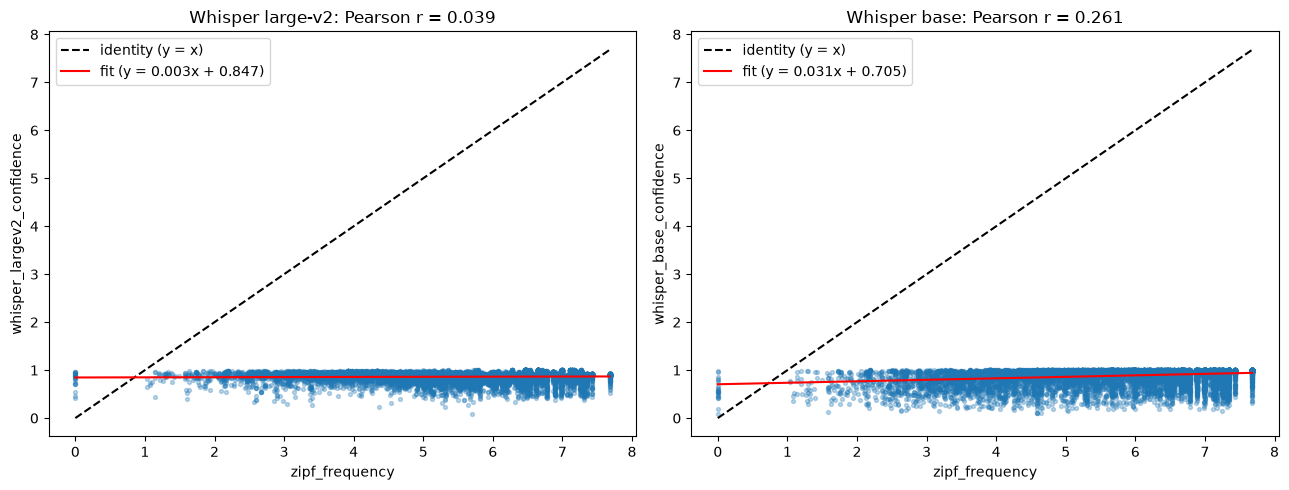

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr

WHISPER_MODELS = {
    "Whisper large-v2": ("whisper_largev2_confidence", "low_large_confidence"),
    "Whisper base": ("whisper_base_confidence", "low_base_confidence"),
}

# 1. Confidence vs Zipf frequency scatter, with identity and fitted lines
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, (conf_col, _)) in zip(axes, WHISPER_MODELS.items()):
    x, y = all_events["zipf_frequency"], all_events[conf_col]
    r, _p = pearsonr(x, y)
    slope, intercept = np.polyfit(x, y, 1)
    ax.scatter(x, y, s=8, alpha=0.3)
    grid = np.array([x.min(), x.max()])
    ax.plot(grid, grid, "k--", label="identity (y = x)")
    ax.plot(grid, slope * grid + intercept, "r-", label=f"fit (y = {slope:.3f}x + {intercept:.3f})")
    ax.set_xlabel("zipf_frequency")
    ax.set_ylabel(conf_col)
    ax.set_title(f"{name}: Pearson r = {r:.3f}")
    ax.legend()
fig.tight_layout()
plt.show()

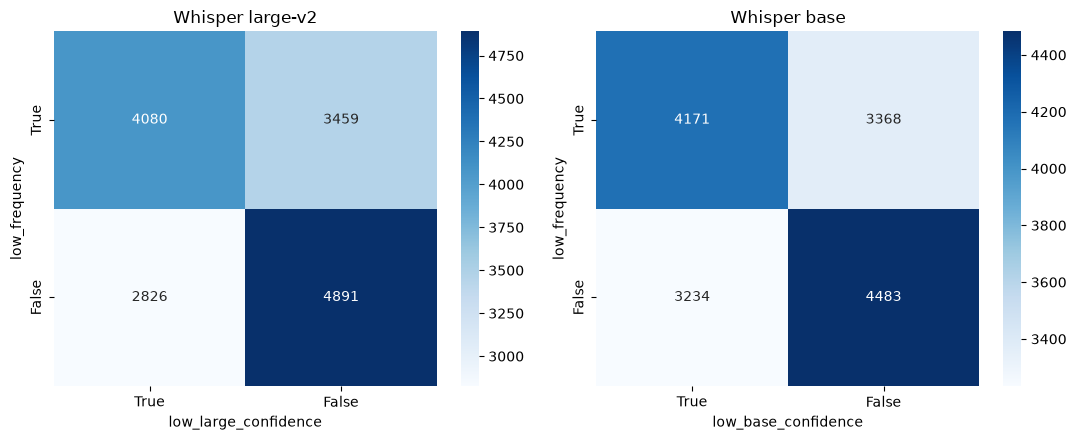

In [7]:
# 2. 2x2 contingency tables: low_frequency vs low confidence
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, (_, low_col)) in zip(axes, WHISPER_MODELS.items()):
    table = pd.crosstab(
        all_events["low_frequency"], all_events[low_col]
    ).reindex(index=[True, False], columns=[True, False], fill_value=0)
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues", cbar=True, ax=ax)
    ax.set_title(name)
    ax.set_xlabel(low_col)
    ax.set_ylabel("low_frequency")
fig.tight_layout()
plt.show()

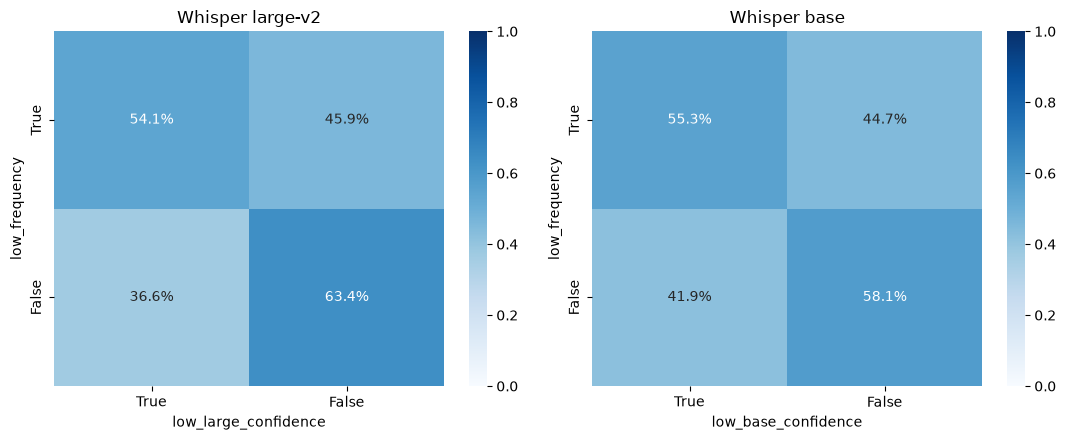

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, (_, low_col)) in zip(axes, WHISPER_MODELS.items()):
    table = pd.crosstab(
        all_events["low_frequency"], all_events[low_col],
        normalize="index"
    ).reindex(index=[True, False], columns=[True, False], fill_value=0)

    sns.heatmap(table, annot=True, fmt=".1%", cmap="Blues",
                vmin=0, vmax=1, cbar=True, ax=ax)
    ax.set_title(name)
    ax.set_xlabel(low_col)
    ax.set_ylabel("low_frequency")

fig.tight_layout()
plt.show()

In [15]:
all_events.groupby("low_frequency")[['whisper_base_confidence', 'whisper_largev2_confidence']].median()

,whisper_base_confidence,whisper_largev2_confidence
low_frequency,,
False,0.973,0.896
True,0.948,0.873


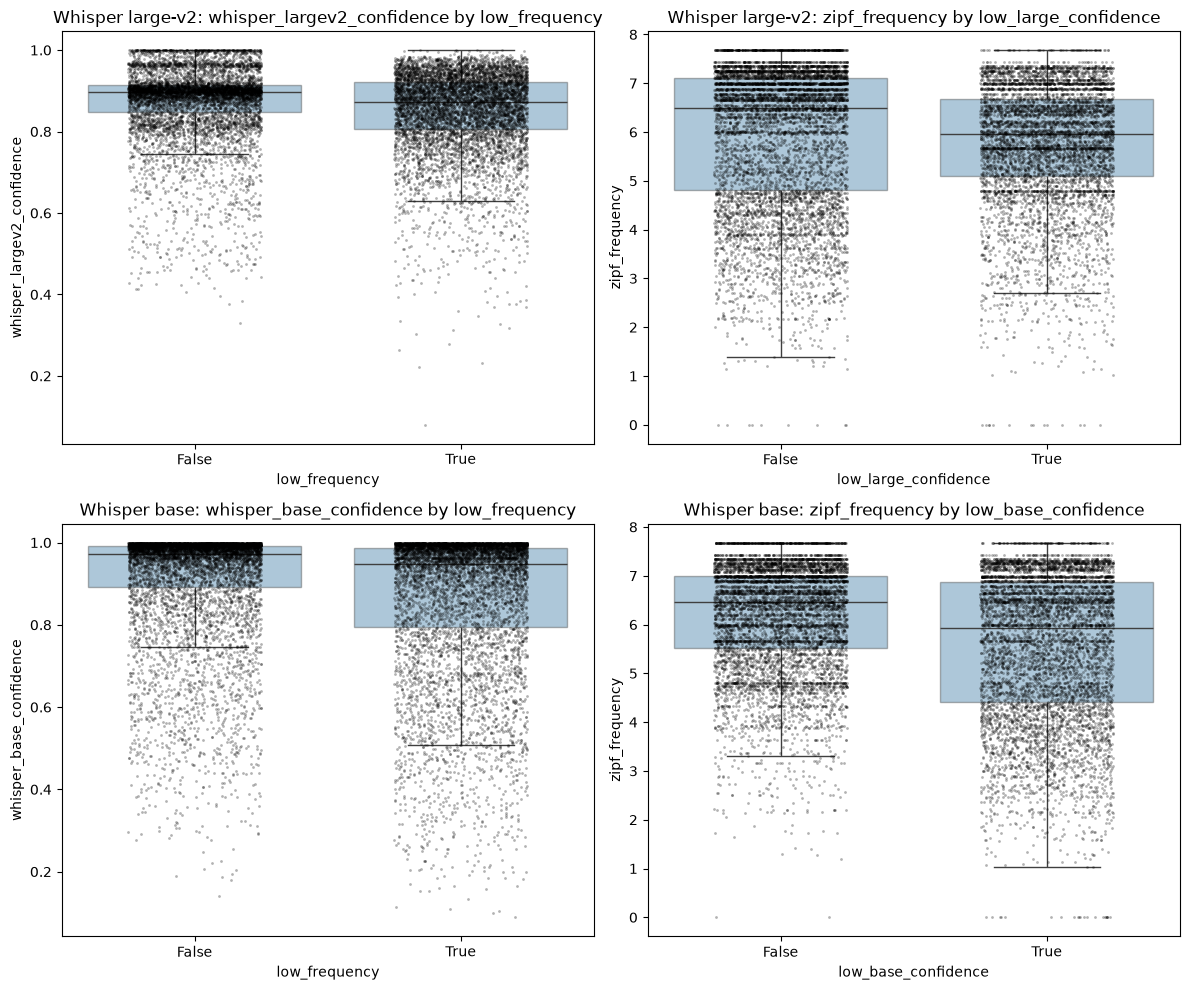

In [8]:
# 3. Boxplots with jittered individual points; one row per Whisper model
fig, axes = plt.subplots(len(WHISPER_MODELS), 2, figsize=(12, 10))
for row, (name, (conf_col, low_col)) in zip(axes, WHISPER_MODELS.items()):
    for ax, (x_col, y_col) in zip(row, [("low_frequency", conf_col), (low_col, "zipf_frequency")]):
        sns.boxplot(data=all_events, x=x_col, y=y_col, order=[False, True],
                    showfliers=False, boxprops={"alpha": 0.4}, ax=ax)
        sns.stripplot(data=all_events, x=x_col, y=y_col, order=[False, True],
                      jitter=0.25, size=2, alpha=0.3, color="k", ax=ax)
        ax.set_title(f"{name}: {y_col} by {x_col}")
fig.tight_layout()
plt.show()